# 06 · Differential cell-type abundance in IPF

**Question:** which cell types/states expand or contract in IPF lungs?

**Statistical considerations**
* The replicate is the **donor** (n = 10 control vs 12 IPF), not the cell.
* Proportions are **compositional**: an expansion of one population necessarily
  lowers the proportions of the others. scCODA models this explicitly
  (Dirichlet-multinomial with a reference cell type); propeller uses
  logit-transformed proportions with moderated t-tests.
* Dissociation and capture efficiency differ between compartments (e.g. immune
  cells dissociate easily; fibroblasts are under-represented in droplet data).
  Abundance is therefore also tested **within each compartment** (e.g. AT2 as a
  fraction of all epithelial cells), which is far less sensitive to such biases.
* **Milo** (Dann *et al.* 2022) tests differential abundance on overlapping kNN
  neighbourhoods and does not depend on discrete cluster boundaries - useful for
  continuous transitions such as AT2 → transitional → aberrant basaloid.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

from ipfatlas import composition
from ipfatlas.config import rscript, setup
from ipfatlas.plotting import (
    COMPARTMENT_COLORS,
    CONDITION_COLORS,
    figsize,
    panel_label,
    save_figure,
    set_style,
)
from ipfatlas.utils import log, write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "06_composition"
TAB = P.tables / "06_composition"
C = cfg["contrast"]
CASE, CTRL = C["case"], C["control"]
R = rscript(cfg)

adata = sc.read_h5ad(P.processed / "discovery_annotated.h5ad")
ct_order = list(adata.obs["cell_type"].cat.categories)
ct_comp = adata.obs.groupby("cell_type", observed=True)["compartment"].first()
ct_pal = dict(zip(ct_order, adata.uns["cell_type_colors"]))
adata

AnnData object with n_obs × n_vars = 132455 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'mk_proliferation', 'celltypist', 'celltypist_conf', 'compartment_l1', 'subcluster', 'cell_type', 'cell_type_reason', 'compartment', 'harmonised_celltype'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_m

## 1. Composition of every donor (all diagnoses)

J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_31220\2228394742.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  comp_prop = (counts_all.T.groupby(ct_comp).sum().T).div(counts_all.sum(axis=1), axis=0)


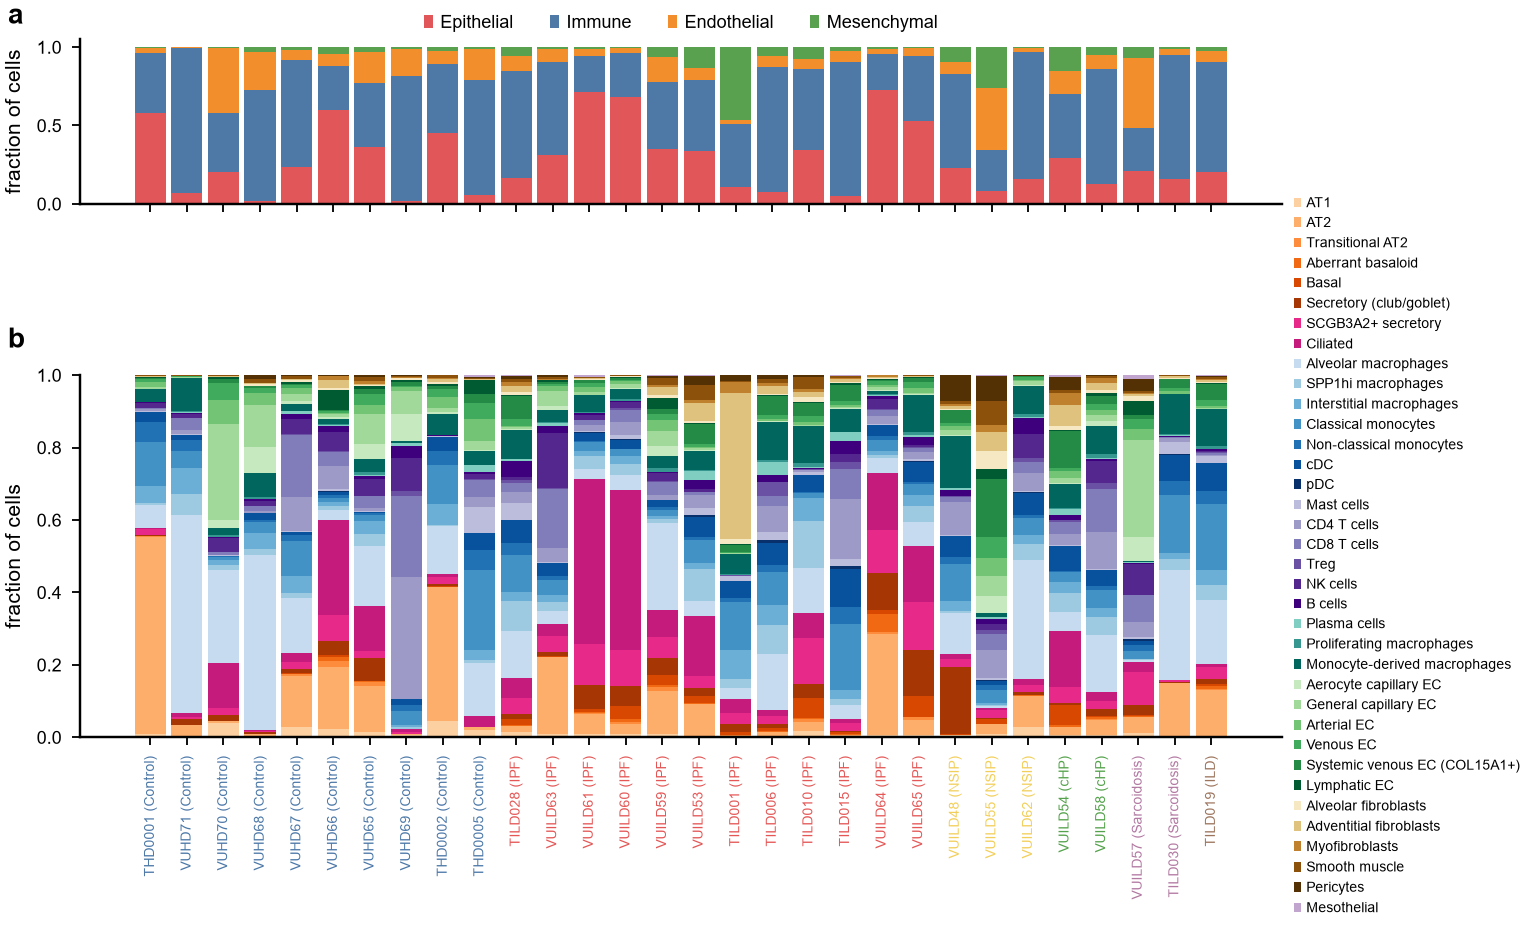

WindowsPath('J:/Portfolio_projects/Projects/scRNA/results/tables/06_composition/cell_type_proportions_per_donor.csv')

In [2]:
counts_all, meta_all = composition.donor_counts(adata, "cell_type", "donor_id", "diagnosis", extra=["site", "sex"])
prop_all = counts_all.div(counts_all.sum(axis=1), axis=0)
dx_order = ["Control", "IPF", "NSIP", "cHP", "Sarcoidosis", "ILD"]
donor_order = meta_all.assign(dx=pd.Categorical(meta_all["diagnosis"], dx_order)).sort_values(["dx"]).index
comp_prop = (counts_all.T.groupby(ct_comp).sum().T).div(counts_all.sum(axis=1), axis=0)

fig, axes = plt.subplots(2, 1, figsize=figsize(183, 110), sharex=True, gridspec_kw={"height_ratios": [1, 2.2]})
bottom = np.zeros(len(donor_order))
for comp in ["Epithelial", "Immune", "Endothelial", "Mesenchymal"]:
    v = comp_prop.loc[donor_order, comp].to_numpy()
    axes[0].bar(range(len(donor_order)), v, bottom=bottom, color=COMPARTMENT_COLORS[comp], label=comp, width=0.85)
    bottom += v
axes[0].set_ylabel("fraction of cells")
axes[0].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.25))
bottom = np.zeros(len(donor_order))
for ct in ct_order:
    v = prop_all.loc[donor_order, ct].to_numpy()
    axes[1].bar(range(len(donor_order)), v, bottom=bottom, color=ct_pal[ct], label=ct, width=0.85)
    bottom += v
axes[1].set_ylabel("fraction of cells")
axes[1].legend(ncol=1, fontsize=4.5, loc="center left", bbox_to_anchor=(1.0, 0.5))
axes[1].set_xticks(range(len(donor_order)))
axes[1].set_xticklabels([f"{d} ({meta_all.loc[d, 'diagnosis']})" for d in donor_order], rotation=90, fontsize=4.5)
for t, d in zip(axes[1].get_xticklabels(), donor_order):
    t.set_color(CONDITION_COLORS.get(meta_all.loc[d, "diagnosis"], "black"))
panel_label(axes[0], "a", x=-0.06)
panel_label(axes[1], "b", x=-0.06)
fig.tight_layout()
save_figure(fig, "S6_composition_per_donor", FIG)
plt.show()
write_table(prop_all.round(4), TAB / "cell_type_proportions_per_donor")

## 2. propeller — all cells and within compartments (IPF vs control)

In [3]:
sub = adata[adata.obs["diagnosis"].isin([CASE, CTRL])].copy()
for c in ["cell_type", "donor_id", "diagnosis"]:
    sub.obs[c] = sub.obs[c].cat.remove_unused_categories()
print(sub.obs.groupby("diagnosis", observed=True)["donor_id"].nunique())

res = {}
res["all cells"] = composition.run_propeller(sub, R, P.r_scripts / "propeller.R", P.interim / "propeller",
                                             "cell_type", "donor_id", "diagnosis", CASE, CTRL,
                                             covariates=["sex"], tag="_all")
for comp in ["Epithelial", "Immune", "Endothelial", "Mesenchymal"]:
    s = sub[sub.obs["compartment"] == comp].copy()
    s.obs["cell_type"] = s.obs["cell_type"].cat.remove_unused_categories()
    res[comp] = composition.run_propeller(s, R, P.r_scripts / "propeller.R", P.interim / "propeller",
                                          "cell_type", "donor_id", "diagnosis", CASE, CTRL,
                                          covariates=["sex"], tag=f"_{comp}")
prop_tab = []
for scope, r in res.items():
    r = r.copy()
    r["scope"] = scope
    prop_tab.append(r)
prop_tab = pd.concat(prop_tab, ignore_index=True)
prop_tab["log2_prop_ratio"] = np.log2(prop_tab["PropRatio"])
write_table(prop_tab, TAB / "propeller_results", index=False)
within = prop_tab[prop_tab["scope"] != "all cells"].set_index("celltype")
within[["log2_prop_ratio", "P.Value", "FDR"]].sort_values("FDR").round(4)

diagnosis
Control    10
IPF        12
Name: donor_id, dtype: int64
05:08:24 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_all.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_all.csv IPF Control sex


05:08:30 | INFO | R finished: propeller.R
26:       Non-classical monocytes  0.5966498 3.015553e-01 4.175382e-01
27:                     Pericytes  2.3828348 4.032959e-01 5.377278e-01
28:                  Plasma cells  2.1650184 4.337679e-01 5.577016e-01
29:                 Smooth muscle  2.3591145 4.730150e-01 5.871910e-01
30:                   CD4 T cells  0.6932478 5.411123e-01 6.439062e-01
31:                           AT2  0.5227693 5.544748e-01 6.439062e-01
32:                     Venous EC  0.5508735 5.774639e-01 6.496468e-01
33:          Alveolar fibroblasts  1.4467113 6.304020e-01 6.877112e-01
34:                   CD8 T cells  0.6137502 7.473286e-01 7.912891e-01
35:      Interstitial macrophages  0.8604213 7.836309e-01 8.060204e-01
36:           Classical monocytes  0.8886838 9.149895e-01 9.149895e-01
                         celltype  PropRatio      P.Value          FDR
                           <char>      <num>        <num>        <num>

Performing logit transformation of

05:08:31 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_Epithelial.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_Epithelial.csv IPF Control sex


05:08:36 | INFO | R finished: propeller.R
celltype  PropRatio      P.Value          FDR
                    <char>      <num>        <num>        <num>
1:                   Basal 24.1946397 7.405311e-07 5.924249e-06
2:      SCGB3A2+ secretory  2.4041277 4.398883e-03 1.154043e-02
3:                     AT1  0.2600886 5.155336e-03 1.154043e-02
4:       Aberrant basaloid  6.1174896 5.770215e-03 1.154043e-02
5:                     AT2  0.4529020 1.336773e-02 2.138837e-02
6: Secretory (club/goblet)  1.3781891 2.893851e-02 3.858468e-02
7:                Ciliated  1.2470745 1.001386e-01 1.144441e-01
8:        Transitional AT2  0.7507255 9.693007e-01 9.693007e-01

Performing logit transformation of proportions


05:08:37 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_Immune.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_Immune.csv IPF Control sex


05:08:43 | INFO | R finished: propeller.R
 4:                         Treg 2.5844722 0.026419787 0.10567915
 5: Monocyte-derived macrophages 1.8064634 0.047480164 0.13033542
 6:                   Mast cells 1.6495072 0.048875783 0.13033542
 7:    Proliferating macrophages 1.5877519 0.112998926 0.24266166
 8:                      B cells 1.7504268 0.121330829 0.24266166
 9:                 Plasma cells 2.4280595 0.206050852 0.36631263
10:                     NK cells 0.7572626 0.267572250 0.42811560
11:                  CD4 T cells 0.8197081 0.346367245 0.47829591
12:         Alveolar macrophages 0.5095708 0.358721935 0.47829591
13:      Non-classical monocytes 0.5909707 0.481738645 0.59290910
14:          Classical monocytes 0.9758548 0.717300481 0.81977198
15:     Interstitial macrophages 1.0237162 0.806996838 0.86079663
16:                  CD8 T cells 0.7799092 0.995834457 0.99583446

Performing logit transformation of proportions


05:08:43 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_Endothelial.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_Endothelial.csv IPF Control sex


05:08:49 | INFO | R finished: propeller.R
celltype PropRatio      P.Value          FDR
                          <char>     <num>        <num>        <num>
1: Systemic venous EC (COL15A1+) 6.7579976 4.267174e-05 0.0002560305
2:         Aerocyte capillary EC 0.3998852 3.545071e-02 0.0851796700
3:          General capillary EC 0.5229835 4.258984e-02 0.0851796700
4:                     Venous EC 0.9544748 6.316165e-01 0.7400999037
5:                   Arterial EC 0.7750972 6.493469e-01 0.7400999037
6:                  Lymphatic EC 0.4884594 7.400999e-01 0.7400999037

Performing logit transformation of proportions


05:08:49 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_Mesenchymal.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_Mesenchymal.csv IPF Control sex


05:08:55 | INFO | R finished: propeller.R
celltype PropRatio   P.Value       FDR
                    <char>     <num>     <num>     <num>
1: Adventitial fibroblasts 1.3346533 0.1378486 0.5739361
2:    Alveolar fibroblasts 0.6595202 0.1913120 0.5739361
3:               Pericytes 0.6965000 0.4481273 0.6581602
4:          Myofibroblasts 1.1728649 0.4578033 0.6581602
5:           Smooth muscle 1.0934325 0.5484668 0.6581602
6:             Mesothelial 0.7299188 0.8965568 0.8965568

Performing logit transformation of proportions


,log2_prop_ratio,P.Value,FDR
celltype,,,
Basal,4.5966,0.0000,0.0000
Systemic venous EC (COL15A1+),2.7566,0.0000,0.0003
AT1,-1.9429,0.0052,0.0115
SCGB3A2+ secretory,1.2655,0.0044,0.0115
Aberrant basaloid,2.6129,0.0058,0.0115
cDC,1.4718,0.0011,0.0183
AT2,-1.1427,0.0134,0.0214
SPP1hi macrophages,1.7913,0.0031,0.0225
pDC,2.3269,0.0042,0.0225


## 3. scCODA — Bayesian compositional model within compartments
The reference cell type is chosen automatically as the type with the least
variable relative abundance across donors (present in ≥95 % of donors). An
effect is "credible" if its spike-and-slab inclusion probability exceeds the
threshold controlling the expected false-discovery rate at 10 %. A chain whose
mean acceptance rate falls outside 0.6–0.95 has not explored the posterior
(pertpy warns at these bounds); it is restarted with the next seed (up to three
tries), and a compartment without a converged chain is reported as such.

In [4]:
sccoda = []
for comp in ["Epithelial", "Immune", "Endothelial", "Mesenchymal"]:
    s = sub[sub.obs["compartment"] == comp]
    cnt, met = composition.donor_counts(s, "cell_type", "donor_id", "diagnosis")
    cnt = cnt.loc[:, cnt.sum() > 0]
    try:
        eff = composition.run_sccoda(cnt, met, "diagnosis", CASE, CTRL, fdr=cfg["composition"]["sccoda_fdr"])
        eff["scope"] = comp
        sccoda.append(eff)
    except Exception as e:  # report and continue: scCODA can fail for degenerate compartments
        log.warning(f"scCODA failed for {comp}: {e}")
sccoda = pd.concat(sccoda, ignore_index=True)
sccoda["credible"] = sccoda["Final Parameter"] != 0
write_table(sccoda, TAB / "sccoda_results", index=False)
sccoda[["scope", "celltype", "Final Parameter", "Inclusion probability", "log2-fold change", "credible",
        "reference_cell_type"]].round(3)

  0%|          | 0/25000 [00:00<?, ?it/s]

warmup:   5%|▌         | 1250/25000 [00:06<02:12, 178.71it/s, 255 steps of size 1.60e-02. acc. prob=0.79]

warmup:  10%|█         | 2500/25000 [00:12<01:49, 206.09it/s, 127 steps of size 2.84e-02. acc. prob=0.79]

warmup:  15%|█▌        | 3750/25000 [00:17<01:34, 223.94it/s, 255 steps of size 2.44e-02. acc. prob=0.80]

warmup:  20%|██        | 5000/25000 [00:22<01:24, 237.94it/s, 255 steps of size 2.76e-02. acc. prob=0.80]

sample:  25%|██▌       | 6250/25000 [00:26<01:15, 247.81it/s, 127 steps of size 2.76e-02. acc. prob=0.80]

... (3,063 outputs left out)

sample: 100%|██████████| 25000/25000 [01:01<00:00, 523.35it/s, 63 steps of size 6.42e-02. acc. prob=0.74]

sample: 100%|██████████| 25000/25000 [01:01<00:00, 405.54it/s, 63 steps of size 6.42e-02. acc. prob=0.74]

05:18:03 | INFO | scCODA reference cell type: Myofibroblasts; acceptance rate 0.74 (rng_key=1); credible effects: 0


,scope,celltype,Final Parameter,Inclusion probability,log2-fold change,credible,reference_cell_type
0,Epithelial,AT1,0.000,0.434,-0.666,False,Secretory (club/goblet)
1,Epithelial,AT2,0.000,0.518,-0.666,False,Secretory (club/goblet)
2,Epithelial,Transitional AT2,0.000,0.362,-0.666,False,Secretory (club/goblet)
3,Epithelial,Aberrant basaloid,0.000,0.561,-0.666,False,Secretory (club/goblet)
4,Epithelial,Basal,1.182,0.979,1.039,True,Secretory (club/goblet)
5,Epithelial,Secretory (club/goblet),0.000,0.000,-0.666,False,Secretory (club/goblet)
6,Epithelial,SCGB3A2+ secretory,1.016,0.971,0.799,True,Secretory (club/goblet)
7,Epithelial,Ciliated,0.866,0.943,0.584,True,Secretory (club/goblet)
8,Immune,Alveolar macrophages,0.000,0.417,-0.267,False,Plasma cells
9,Immune,SPP1hi macrophages,0.777,0.936,0.853,True,Plasma cells


## 4. Consensus table

In [5]:
cons = within[["log2_prop_ratio", "FDR"]].rename(columns={"FDR": "propeller_FDR_within"})
cons["propeller_FDR_all"] = prop_tab[prop_tab["scope"] == "all cells"].set_index("celltype")["FDR"]
sc_idx = sccoda.set_index("celltype")
cons["scCODA_log2FC"] = sc_idx["log2-fold change"]
cons["scCODA_credible"] = sc_idx["credible"]
cons["compartment"] = ct_comp
cons["robust"] = (cons["propeller_FDR_within"] < 0.05) & cons["scCODA_credible"].fillna(False).astype(bool)
cons["direction"] = np.where(cons["log2_prop_ratio"] > 0, f"up in {CASE}", f"down in {CASE}")
cons = cons.sort_values(["compartment", "log2_prop_ratio"])
write_table(cons, TAB / "composition_consensus")
cons.round(3)

,log2_prop_ratio,propeller_FDR_within,propeller_FDR_all,scCODA_log2FC,scCODA_credible,compartment,robust,direction
celltype,,,,,,,,
Aerocyte capillary EC,-1.322,0.085,0.110,-0.334,False,Endothelial,False,down in IPF
Lymphatic EC,-1.034,0.740,0.418,-0.334,False,Endothelial,False,down in IPF
General capillary EC,-0.935,0.085,0.110,-0.334,False,Endothelial,False,down in IPF
Arterial EC,-0.368,0.740,0.418,-0.334,False,Endothelial,False,down in IPF
Venous EC,-0.067,0.740,0.650,-0.334,False,Endothelial,False,down in IPF
Systemic venous EC (COL15A1+),2.757,0.000,0.093,1.422,True,Endothelial,True,up in IPF
AT1,-1.943,0.012,0.418,-0.666,False,Epithelial,False,down in IPF
AT2,-1.143,0.021,0.644,-0.666,False,Epithelial,False,down in IPF
Transitional AT2,-0.414,0.969,0.418,-0.666,False,Epithelial,False,down in IPF


J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_31220\2183703693.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  comp_tot = cnt_s.T.groupby(ct_comp).sum().T


J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_31220\2183703693.py:27: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.tight_layout()
J:\Portfolio_projects\Projects\scRNA\src\ipfatlas\plotting.py:114: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  Returns the list of written paths.


J:\Portfolio_projects\Projects\scRNA\src\ipfatlas\plotting.py:114: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  Returns the list of written paths.
J:\Portfolio_projects\Projects\scRNA\src\ipfatlas\plotting.py:114: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  Returns the list of written paths.


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


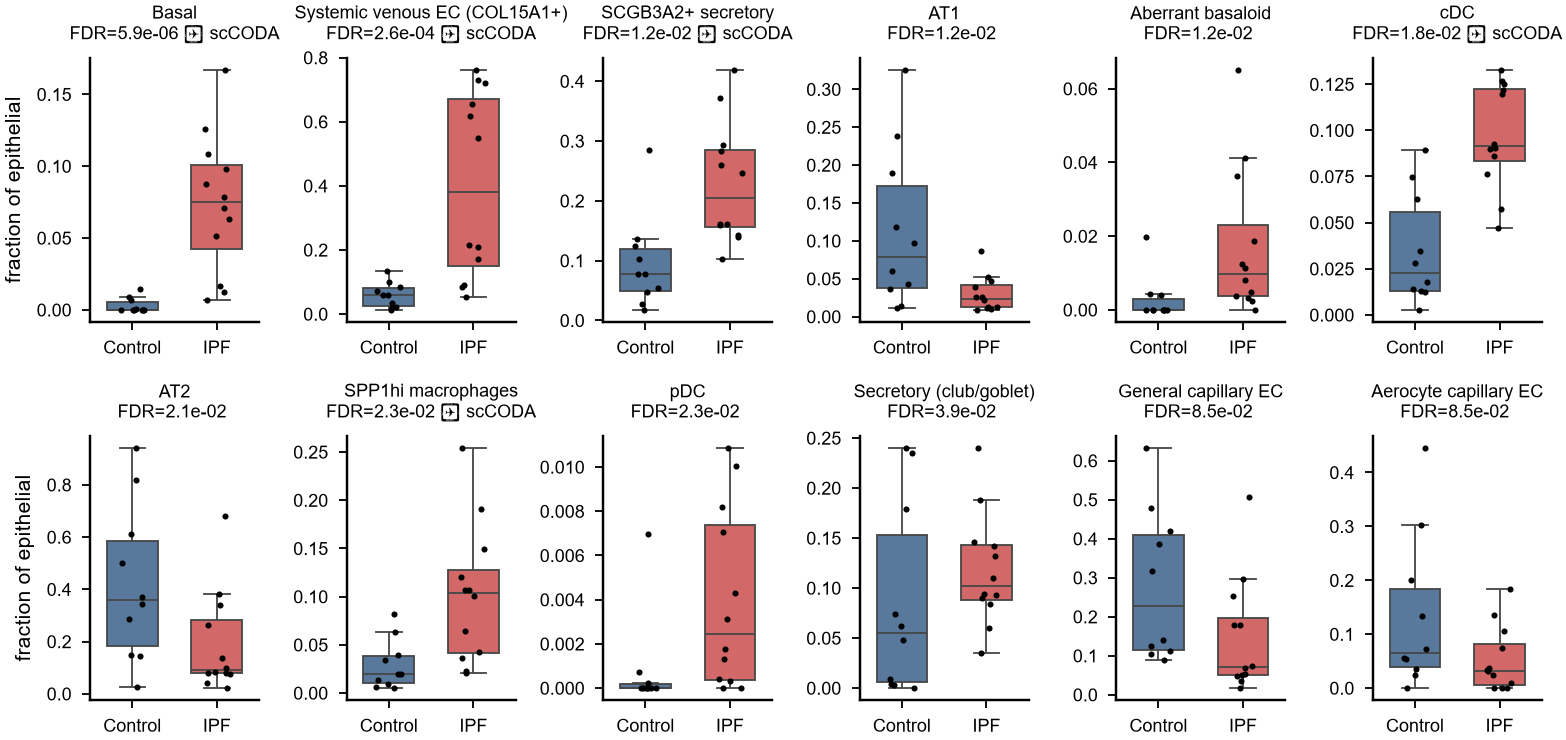

In [6]:
plot_types = cons.sort_values("propeller_FDR_within").index[:12].tolist()
long = composition.proportions_long(*composition.donor_counts(sub, "cell_type", "donor_id", "diagnosis"), "diagnosis")
# proportions within compartment for plotting
cnt_s, met_s = composition.donor_counts(sub, "cell_type", "donor_id", "diagnosis")
comp_tot = cnt_s.T.groupby(ct_comp).sum().T
within_prop = cnt_s.copy().astype(float)
for ct in cnt_s.columns:
    within_prop[ct] = cnt_s[ct] / comp_tot[ct_comp[ct]].replace(0, np.nan)
wl = within_prop.reset_index().melt(id_vars="donor_id", var_name="cell_type", value_name="fraction")
wl["diagnosis"] = wl["donor_id"].map(met_s["diagnosis"])

ncol = 6
nrow = int(np.ceil(len(plot_types) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=figsize(183, 45 * nrow))
for ax, ct in zip(axes.ravel(), plot_types):
    d = wl[wl["cell_type"] == ct]
    sns.boxplot(data=d, x="diagnosis", y="fraction", order=[CTRL, CASE], hue="diagnosis", palette=CONDITION_COLORS,
                width=0.6, fliersize=0, linewidth=0.6, ax=ax, legend=False)
    sns.stripplot(data=d, x="diagnosis", y="fraction", order=[CTRL, CASE], color="black", size=2, ax=ax, jitter=0.15)
    fdr = cons.loc[ct, "propeller_FDR_within"]
    star = "✓ scCODA" if bool(cons.loc[ct, "scCODA_credible"]) else ""
    ax.set_title(f"{ct}\nFDR={fdr:.1e} {star}", fontsize=6)
    ax.set_xlabel("")
    ax.set_ylabel(f"fraction of {ct_comp[ct].lower()}" if ax in axes[:, 0] else "")
for ax in axes.ravel()[len(plot_types):]:
    ax.axis("off")
fig.tight_layout()
save_figure(fig, "Fig2_composition_top_celltypes", FIG)
plt.show()

## 5. Milo — neighbourhood-level differential abundance

In [7]:
import pertpy as pt

milo = pt.tl.Milo()
msub = sub.copy()
sc.pp.neighbors(msub, use_rep="X_integrated", n_neighbors=30, random_state=0)
mdata = milo.load(msub)
milo.make_nhoods(mdata["rna"], prop=0.05, seed=0)
mdata = milo.count_nhoods(mdata, sample_col="donor_id")
mdata["rna"].obs["diagnosis"] = pd.Categorical(mdata["rna"].obs["diagnosis"], categories=[CTRL, CASE])
milo.da_nhoods(mdata, design="~sex+diagnosis", model_contrasts=f"diagnosis{CASE}", solver="pydeseq2")
milo.annotate_nhoods(mdata, anno_col="cell_type")
nh = mdata["milo"].var.copy()
nh["nhood_annotation"] = nh["nhood_annotation"].astype(str)  # categorical: "Mixed" is not a category
nh.loc[nh["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"
mdata["milo"].var["nhood_annotation"] = nh["nhood_annotation"]
write_table(nh, TAB / "milo_neighbourhoods")
print(f"{len(nh)} neighbourhoods, {(nh['SpatialFDR'] < 0.1).sum()} with SpatialFDR < 0.1")

Fitting size factors...
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\pydeseq2\dds.py:539: UserWarning: Every gene contains at least one zero, cannot compute log geometric means. Switching to iterative mode.
  self.fit_size_factors(


Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...


... done in 0.36 seconds.

Fitting MAP dispersions...


... done in 0.33 seconds.



Fitting dispersions...


... (32 outputs left out)

... done in 0.12 seconds.

Running Wald tests...


... done in 0.25 seconds.



Log2 fold change & Wald test p-value: diagnosis IPF vs Control
      baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0     8.928012       -1.136007  0.794450 -1.429929  0.152737  0.355948
1     3.522924       -1.788873  1.526152 -1.172146  0.241138  0.452275
2     1.887575       -2.037160  1.310247 -1.554791  0.119996       NaN
3     7.214101       -3.288944  1.294834 -2.540051  0.011084  0.090301
4     4.449930       -2.928109  0.960986 -3.046985  0.002311  0.048653
...        ...             ...       ...       ...       ...       ...
3970  2.076435        0.526184  1.075556  0.489221  0.624686  0.769327
3971  1.198378       -0.452651  1.028587 -0.440071  0.659886       NaN
3972  1.588972        0.489695  1.081618  0.452743  0.650734       NaN
3973  1.731982        1.249843  1.115819  1.120113  0.262666       NaN
3974  1.665610       -0.196152  0.861462 -0.227697  0.819882       NaN

[3975 rows x 6 columns]


3975 neighbourhoods, 333 with SpatialFDR < 0.1


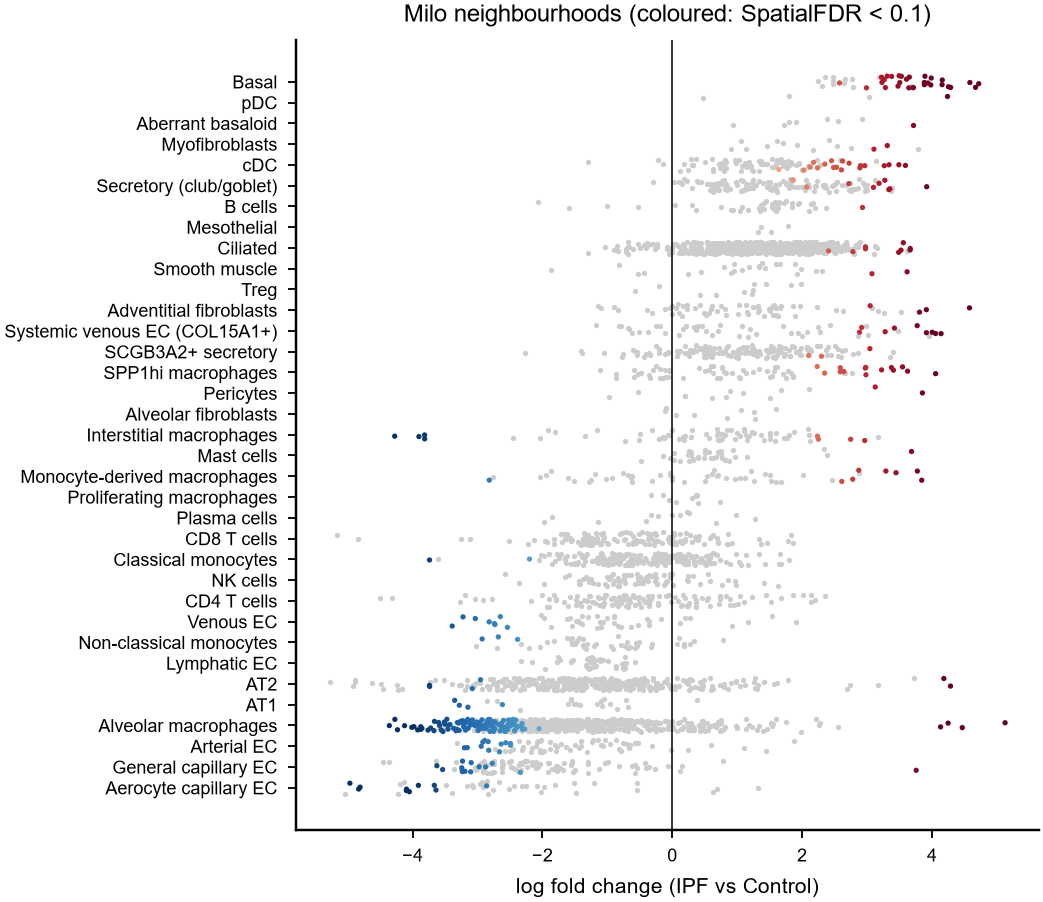

In [8]:
d = nh[nh["nhood_annotation"] != "Mixed"].copy()
order = d.groupby("nhood_annotation")["logFC"].median().sort_values().index
fig, ax = plt.subplots(figsize=figsize(110, 120))
rng = np.random.default_rng(0)
for i, ct in enumerate(order):
    v = d[d["nhood_annotation"] == ct]
    y = i + rng.uniform(-0.3, 0.3, len(v))
    sig = v["SpatialFDR"] < 0.1
    ax.scatter(v.loc[~sig, "logFC"], y[~sig.to_numpy()], s=3, color="#CCCCCC", lw=0)
    ax.scatter(v.loc[sig, "logFC"], y[sig.to_numpy()], s=3, c=v.loc[sig, "logFC"], cmap="RdBu_r", vmin=-4, vmax=4, lw=0)
ax.axvline(0, color="black", lw=0.5)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel(f"log fold change ({CASE} vs {CTRL})")
ax.set_title("Milo neighbourhoods (coloured: SpatialFDR < 0.1)")
save_figure(fig, "Fig2_milo_beeswarm", FIG)
plt.show()

## 6. Sensitivity: Vanderbilt-only donors
Vanderbilt is the only site that contributed both controls and IPF; repeating
the within-compartment test there removes the site-disease confounding.

diagnosis
Control    7
IPF        7
Name: donor_id, dtype: int64


05:20:00 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_VU_Epithelial.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_VU_Epithelial.csv IPF Control none


05:20:05 | INFO | R finished: propeller.R
celltype  PropRatio     P.Value       FDR
                    <char>      <num>       <num>     <num>
1:                   Basal 14.5955673 0.001534423 0.0095934
2:                     AT1  0.1531865 0.002398350 0.0095934
3:       Aberrant basaloid  4.6277490 0.135368677 0.3609831
4:        Transitional AT2  0.4776758 0.236627146 0.4273982
5:      SCGB3A2+ secretory  1.2968090 0.267123869 0.4273982
6:                Ciliated  1.2199634 0.536923837 0.6870085
7:                     AT2  0.8178615 0.601132467 0.6870085
8: Secretory (club/goblet)  0.9373510 0.901184917 0.9011849

Performing logit transformation of proportions


05:20:06 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_VU_Immune.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_VU_Immune.csv IPF Control none


05:20:12 | INFO | R finished: propeller.R
 4: Monocyte-derived macrophages 2.0199513 0.0953789236 0.381515694
 5:                   Mast cells 3.2440622 0.1333142337 0.426605548
 6:          Classical monocytes 1.6390782 0.1729135894 0.441191551
 7:    Proliferating macrophages 1.4709478 0.1975427645 0.441191551
 8:                         Treg 1.1980164 0.2479732059 0.441191551
 9:                 Plasma cells 2.8759449 0.2481702475 0.441191551
10:                      B cells 1.3952331 0.3146080270 0.503372843
11:                  CD4 T cells 0.6268845 0.4273678945 0.621626028
12:         Alveolar macrophages 0.4893192 0.4865013345 0.648668446
13:                     NK cells 0.9321091 0.7782062344 0.899004626
14:     Interstitial macrophages 0.9608811 0.8159546318 0.899004626
15:      Non-classical monocytes 1.0959715 0.8428168372 0.899004626
16:                  CD8 T cells 0.8106361 0.9163698081 0.916369808

Performing logit transformation of proportions


05:20:12 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_VU_Endothelial.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_VU_Endothelial.csv IPF Control none


05:20:18 | INFO | R finished: propeller.R
celltype PropRatio    P.Value        FDR
                          <char>     <num>      <num>      <num>
1: Systemic venous EC (COL15A1+) 5.5046164 0.00446903 0.02681418
2:         Aerocyte capillary EC 0.4542798 0.07555009 0.22665026
3:                   Arterial EC 1.7204917 0.20741471 0.38496437
4:          General capillary EC 0.6415118 0.25664291 0.38496437
5:                     Venous EC 1.1787581 0.40999145 0.49198974
6:                  Lymphatic EC 0.5609573 0.82125524 0.82125524

Performing logit transformation of proportions


05:20:18 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\cells_VU_Mesenchymal.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller\propeller_VU_Mesenchymal.csv IPF Control none


05:20:23 | INFO | R finished: propeller.R
celltype PropRatio   P.Value       FDR
                    <char>     <num>     <num>     <num>
1:             Mesothelial 2.0485532 0.2011781 0.5910715
2:               Pericytes 0.5654816 0.2826622 0.5910715
3: Adventitial fibroblasts 1.2307175 0.3505614 0.5910715
4:    Alveolar fibroblasts 0.5863816 0.3940477 0.5910715
5:           Smooth muscle 1.3434277 0.6575966 0.7891159
6:          Myofibroblasts 0.9493011 0.9556791 0.9556791

Performing logit transformation of proportions


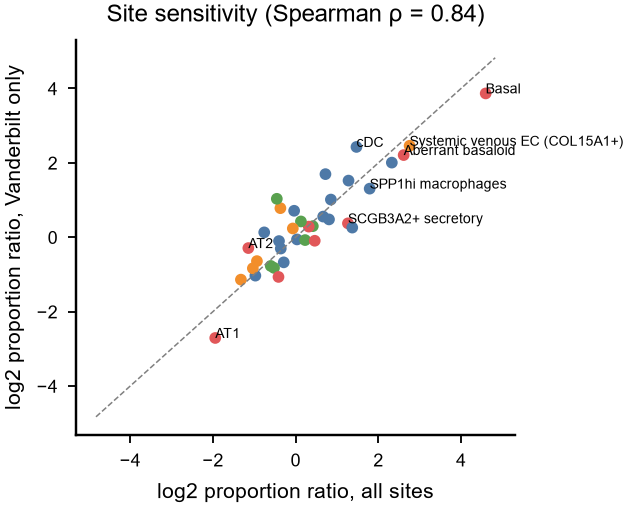

In [9]:
vu = sub[sub.obs["site"] == "Vanderbilt"].copy()
print(vu.obs.groupby("diagnosis", observed=True)["donor_id"].nunique())
sens = []
for comp in ["Epithelial", "Immune", "Endothelial", "Mesenchymal"]:
    s = vu[vu.obs["compartment"] == comp].copy()
    s.obs["cell_type"] = s.obs["cell_type"].cat.remove_unused_categories()
    r = composition.run_propeller(s, R, P.r_scripts / "propeller.R", P.interim / "propeller", "cell_type",
                                  "donor_id", "diagnosis", CASE, CTRL, covariates=None, tag=f"_VU_{comp}")
    sens.append(r)
sens = pd.concat(sens).set_index("celltype")
cmp = pd.DataFrame({"all_sites": cons["log2_prop_ratio"], "vanderbilt_only": np.log2(sens["PropRatio"])}).dropna()
write_table(cmp, TAB / "composition_sensitivity_vanderbilt")
r = cmp.corr(method="spearman").iloc[0, 1]
fig, ax = plt.subplots(figsize=figsize(65, 60))
ax.scatter(cmp["all_sites"], cmp["vanderbilt_only"], s=8, c=[COMPARTMENT_COLORS[ct_comp[c]] for c in cmp.index])
lim = np.nanmax(np.abs(cmp.to_numpy())) * 1.05
ax.plot([-lim, lim], [-lim, lim], ls="--", color="grey", lw=0.5)
for c in cmp.reindex(plot_types).dropna().index[:8]:
    ax.annotate(c, (cmp.loc[c, "all_sites"], cmp.loc[c, "vanderbilt_only"]), fontsize=4.5)
ax.set_xlabel("log2 proportion ratio, all sites")
ax.set_ylabel("log2 proportion ratio, Vanderbilt only")
ax.set_title(f"Site sensitivity (Spearman ρ = {r:.2f})")
save_figure(fig, "S6_composition_site_sensitivity", FIG)
plt.show()